# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors

## 1. Introduction

This chapter explores distance metrics and the K-Nearest Neighbors (KNN) algorithm using Python and scikit-learn. Distance metrics are used to measure the similarity or dissimilarity between data points. These measurements help machine learning models determine how data should be classified or grouped.

KNN is a supervised machine learning algorithm that predicts the class of a new data point by examining its nearest neighbors in the training dataset. The algorithm can also be used for regression tasks, where it predicts numerical values.

In this chapter, we will explore different distance metrics, implement a KNN classifier, optimize its hyperparameters, and evaluate its performance using the Iris dataset.

### Learning Objectives

- Understand distance metrics in machine learning.
- Explain how the K-Nearest Neighbors algorithm works.
- Implement a KNN classification model using scikit-learn.
- Compare different distance metrics.
- Optimize KNN hyperparameters using GridSearchCV.
- Evaluate model performance using accuracy, confusion matrices, and cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    learning_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Introduction to Distance Metrics

Distance metrics are mathematical methods used to measure the distance between data points. In machine learning, distance measurements help determine how similar or different two observations are.

Several distance metrics commonly used in KNN include:

1. **Euclidean Distance:** Measures the straight-line distance between two points.
2. **Manhattan Distance:** Measures the sum of absolute differences between coordinates.
3. **Minkowski Distance:** A generalized distance metric that includes Euclidean and Manhattan distance as special cases.
4. **Cosine Distance:** Measures the difference in direction between two vectors.

The choice of distance metric can affect classification results. Feature scaling is also important because variables with larger numerical ranges may dominate distance calculations.

In [2]:
point_a = np.array([1, 2])
point_b = np.array([4, 6])

euclidean = np.sqrt(np.sum((point_a - point_b) ** 2))
manhattan = np.sum(np.abs(point_a - point_b))

print("Point A:", point_a)
print("Point B:", point_b)
print("Euclidean Distance:", euclidean)
print("Manhattan Distance:", manhattan)

Point A: [1 2]
Point B: [4 6]
Euclidean Distance: 5.0
Manhattan Distance: 7


## 3. Understanding K-Nearest Neighbors

K-Nearest Neighbors (KNN) is a machine learning algorithm that classifies a new observation based on the labels of its nearest neighbors.

The algorithm follows these steps:

1. Select the value of K, which represents the number of neighbors to consider.
2. Calculate the distances between the new observation and the training observations.
3. Identify the K nearest neighbors.
4. Determine the predicted class using the majority vote of those neighbors.
5. Evaluate the prediction using appropriate performance metrics.

A small K value may make the model sensitive to noise, while a larger K value may smooth predictions but overlook local patterns. Therefore, choosing a suitable K value is important for model performance.

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", iris.feature_names)
print("Target classes:", iris.target_names)

Dataset shape: (150, 4)
Target shape: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [5]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

knn_pipeline.fit(X_train, y_train)

y_pred = knn_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("KNN Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

KNN Accuracy: 0.9333333333333333
Accuracy Percentage: 93.33 %


## 4. Comparing Distance Metrics

Different distance metrics can produce different classification results because each metric measures similarity in a different way.

Euclidean distance is useful for measuring straight-line distances. Manhattan distance calculates the total absolute difference across features. Minkowski distance provides a generalized approach, while cosine distance focuses on the angle between vectors.

To understand their effects, we can compare KNN classifiers using several distance metrics on the same training and testing datasets.

The models should use consistent preprocessing and data splits so that their results can be compared fairly.

In [6]:
metrics = [
    "euclidean",
    "manhattan",
    "minkowski",
    "cosine"
]

metric_results = []

for metric in metrics:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=5,
            metric=metric
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    metric_results.append({
        "Distance Metric": metric,
        "Accuracy": accuracy
    })

metric_df = pd.DataFrame(metric_results)
print(metric_df)

  Distance Metric  Accuracy
0       euclidean  0.933333
1       manhattan  0.933333
2       minkowski  0.933333
3          cosine  0.833333


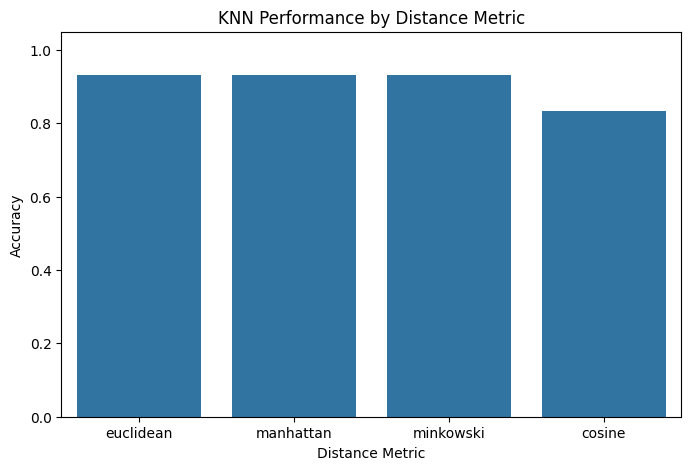

In [7]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=metric_df,
    x="Distance Metric",
    y="Accuracy"
)

plt.title("KNN Performance by Distance Metric")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.xlabel("Distance Metric")
plt.show()

## 5. Hyperparameter Tuning in KNN

Hyperparameters are settings that determine how a machine learning algorithm operates. Unlike model parameters, hyperparameters are selected before or during model selection rather than directly learned as ordinary model coefficients.

In KNN, important hyperparameters include:

- **n_neighbors:** The number of neighbors used for prediction.
- **weights:** Determines whether neighbors contribute equally or according to their distance.
- **metric:** Defines how distances are calculated.

GridSearchCV systematically evaluates the specified combinations of hyperparameters using cross-validation. This helps identify a suitable configuration based on the selected evaluation metric.

In [8]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 5, 'knn__weights': 'uniform'}
Best Cross-Validation Accuracy: 0.9666666666666668


In [9]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred_best)

print("Best Model Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", round(test_accuracy * 100, 2), "%")

Best Model Test Accuracy: 0.9333333333333333
Test Accuracy Percentage: 93.33 %


## 6. Evaluating KNN Performance

Model evaluation helps determine how effectively a trained model predicts unseen observations. Accuracy is useful for measuring the overall proportion of correct predictions, but additional metrics provide more detailed information about classification performance.

Common evaluation techniques include:

1. **Accuracy:** The proportion of correct predictions.
2. **Precision:** The proportion of predicted positive cases that are correct for a particular class.
3. **Recall:** The proportion of actual positive cases correctly identified for a particular class.
4. **F1-score:** The harmonic mean of precision and recall.
5. **Confusion matrix:** A table that compares actual labels with predicted labels.
6. **Cross-validation:** A method for assessing model performance across multiple data splits.

Using several evaluation techniques provides a more complete understanding of model performance.

In [ ]:
print(classification_report(
    y_test,
    y_pred_best,
    target_names=iris.target_names,
    zero_division=0
))

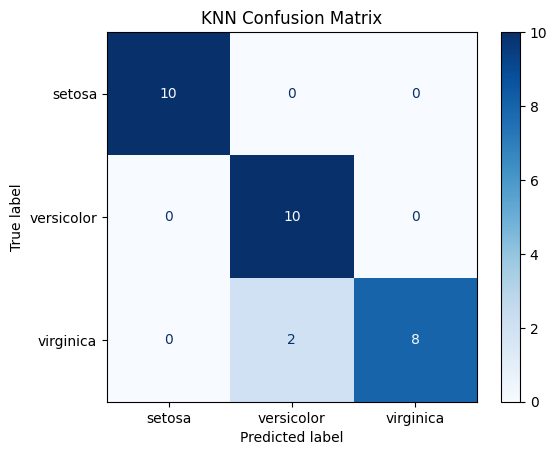

In [10]:
cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

In [11]:
cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross-Validation Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross-Validation Scores: [0.91666667 1.         0.95833333 0.95833333 1.        ]
Mean CV Accuracy: 0.9666666666666668
Standard Deviation: 0.031180478223116186


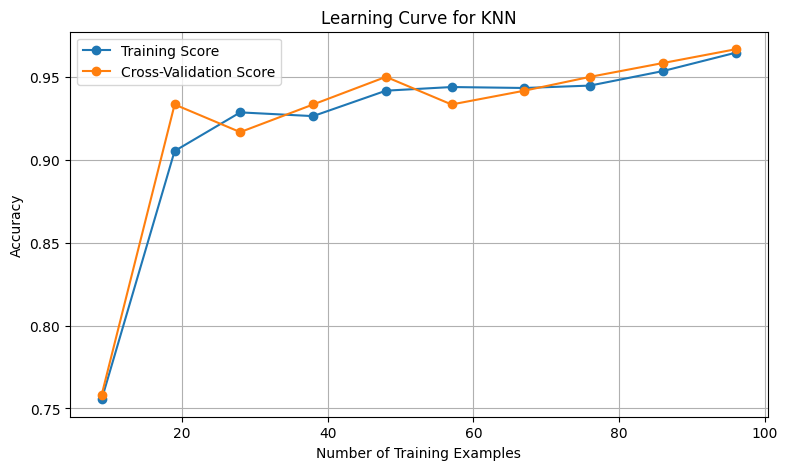

In [12]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training Score"
)

plt.plot(
    train_sizes,
    test_scores.mean(axis=1),
    marker="o",
    label="Cross-Validation Score"
)

plt.xlabel("Number of Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curve for KNN")
plt.legend()
plt.grid(True)
plt.show()

## 7. Practical Exercises

### Exercise 1: Building a KNN Classifier

Build a KNN classifier using the Iris dataset. Split the data into training and testing sets, train the model, and calculate its accuracy.

**Objective:** Understand the basic implementation of KNN classification.

### Exercise 2: Tuning Hyperparameters with Grid Search

Use GridSearchCV to test different values of K, weighting methods, and distance metrics. Identify the best parameter combination.

**Objective:** Understand how hyperparameter tuning can improve model selection.

### Exercise 3: Evaluating a KNN Classifier

Evaluate the selected model using accuracy, a classification report, a confusion matrix, and cross-validation.

**Objective:** Understand how different evaluation techniques describe model performance.

     K  Accuracy
0    1  0.966667
1    2  0.933333
2    3  0.933333
3    4  0.933333
4    5  0.933333
5    6  0.933333
6    7  0.966667
7    8  0.933333
8    9  0.966667
9   10  0.966667
10  11  0.966667
11  12  0.966667
12  13  0.966667
13  14  0.966667
14  15  0.966667


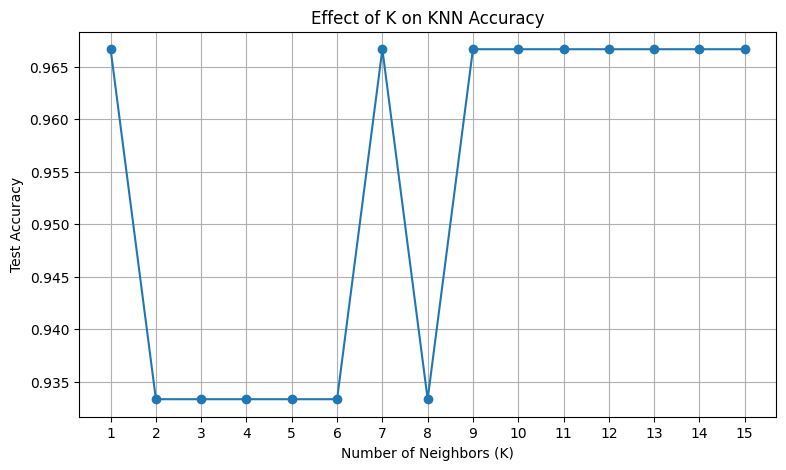

In [13]:
k_results = []

for k in range(1, 16):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    k_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions)
    })

k_df = pd.DataFrame(k_results)

print(k_df)

plt.figure(figsize=(9, 5))
plt.plot(k_df["K"], k_df["Accuracy"], marker="o")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.title("Effect of K on KNN Accuracy")
plt.xticks(range(1, 16))
plt.grid(True)
plt.show()

## 8. Conclusion

In this chapter, we explored distance metrics and the K-Nearest Neighbors algorithm using scikit-learn. We learned how distance metrics measure the similarity between observations and how KNN uses nearby data points to make predictions.

We also compared Euclidean, Manhattan, Minkowski, and cosine distance metrics. Next, we implemented hyperparameter tuning using GridSearchCV to select a suitable combination of K, weighting method, and distance metric.

Finally, we evaluated the model using accuracy, precision, recall, F1-score, confusion matrices, cross-validation, and learning curves.

Overall, this chapter demonstrates that the performance of a KNN model depends on the characteristics of the dataset, feature scaling, the choice of distance metric, and appropriate hyperparameter selection.